# Solving the n-Queens Problem using Local Search

**Lab 04 — Constraint Satisfaction Problems (CSP)**

Complete the notebook from top to bottom. The experiments use fixed random seeds where practical and report empirical results rather than theoretical guarantees.


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# Portable execution setup
# The notebook intentionally does not change to a personal Google Drive path.
# Run it from the extracted project folder in Jupyter or upload it to Colab.
from pathlib import Path
print("Working directory:", Path.cwd())


Working directory: /mnt/data/lab04_work


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


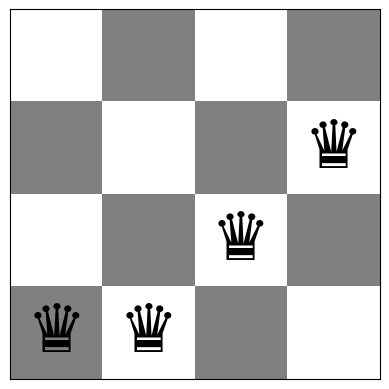

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


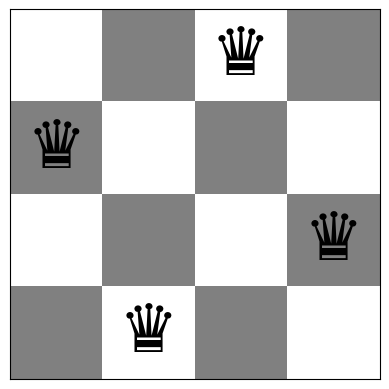

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [5]:
def steepest_ascent_hill_climbing(board):
    current = np.array(board, copy=True)
    n = len(current)
    
    while True:
        current_cost = conflicts(current)
        if current_cost == 0:
            return current, current_cost
        
        best_move = None
        best_cost = current_cost
        for col in range(n):
            original_row = current[col]
            for row in range(n):
                if row != original_row:
                    current[col] = row
                    cost = conflicts(current)
                    if cost < best_cost:
                        best_cost = cost
                        best_move = (col, row)
            current[col] = original_row  # Hoàn tác

        if best_move is None:
            return current, current_cost
            
        current[best_move[0]] = best_move[1]

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [6]:
def inefficient_stochastic_hill_climbing(board):
    current = np.array(board, copy=True)
    n = len(current)
    
    while True:
        current_cost = conflicts(current)
        if current_cost == 0:
            return current, current_cost
            
        uphill_moves = []
        for col in range(n):
            original_row = current[col]
            for row in range(n):
                if row != original_row:
                    current[col] = row
                    cost = conflicts(current)
                    if cost < current_cost:
                        uphill_moves.append((col, row))
            current[col] = original_row
            
        if not uphill_moves:
            return current, current_cost
        chosen_col, chosen_row = uphill_moves[np.random.randint(len(uphill_moves))]
        current[chosen_col] = chosen_row

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [7]:
def efficient_stochastic_hill_climbing(board, max_attempts_factor=100):
    current = np.array(board, copy=True)
    n = len(current)
    max_attempts = max_attempts_factor * n * (n - 1)
    
    attempts = 0
    while attempts < max_attempts:
        current_cost = conflicts(current)
        if current_cost == 0:
            return current, current_cost
        col = np.random.randint(0, n)
        row = np.random.randint(0, n)
        while row == current[col]:
            row = np.random.randint(0, n)
            
        original_row = current[col]
        current[col] = row
        new_cost = conflicts(current)
        
        if new_cost < current_cost:
            attempts = 0
        else:
            current[col] = original_row
            attempts += 1
            
    return current, conflicts(current)

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [8]:
def random_restart_hc(algorithm_fn, n, max_restarts=100):
    best_board = None
    best_cost = float('inf')
    total_runs = 0
    
    for r in range(max_restarts):
        total_runs += 1
        start_board = random_board(n)
        board, cost = algorithm_fn(start_board)
        
        if cost < best_cost:
            best_cost = cost
            best_board = board
            
        if best_cost == 0:
            break
            
    return best_board, best_cost, total_runs

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [9]:
import math

def simulated_annealing(board, max_steps=10000, initial_temp=100.0, cooling_rate=0.995):
    current = np.array(board, copy=True)
    n = len(current)
    current_cost = conflicts(current)
    
    cost_history = [current_cost]
    temp = initial_temp
    
    for step in range(max_steps):
        if current_cost == 0:
            break
            
        temp *= cooling_rate
        if temp < 1e-8:
            break
            
        col = np.random.randint(0, n)
        row = np.random.randint(0, n)
        while row == current[col]:
            row = np.random.randint(0, n)
            
        original_row = current[col]
        current[col] = row
        new_cost = conflicts(current)
        
        delta = new_cost - current_cost
        if delta < 0 or np.random.random() < math.exp(-delta / temp):
            current_cost = new_cost
        else:
            current[col] = original_row
            
        cost_history.append(current_cost)
        
    return current, current_cost, cost_history

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [10]:
import time

def benchmark_algorithms(sizes=[4, 8], num_runs=100):
    results = []
    
    for n in sizes:
        algos = {
            "Steepest asc. HC": lambda b: steepest_ascent_hill_climbing(b),
            "Ineff. Stochastic HC": lambda b: inefficient_stochastic_hill_climbing(b),
            "Efficient Stochastic HC": lambda b: efficient_stochastic_hill_climbing(b),
            "Simulated Annealing": lambda b: simulated_annealing(b)[:2]
        }
        
        for name, fn in algos.items():
            total_time = 0
            total_conflicts = 0
            optimal_count = 0
            
            for _ in range(num_runs):
                init_b = random_board(n)
                t0 = time.perf_counter()
                sol, cost = fn(init_b)
                t1 = time.perf_counter()
                
                total_time += (t1 - t0)
                total_conflicts += cost
                if cost == 0:
                    optimal_count += 1
                    
            avg_time = total_time / num_runs
            avg_conflicts = total_conflicts / num_runs
            opt_pct = (optimal_count / num_runs) * 100
            
            results.append((name, n, f"{avg_time:.6f}s", f"{avg_conflicts:.2f}", f"{opt_pct:.1f}%"))
            
    print(f"{'Algorithm':<25} | {'Size':<5} | {'Avg Time':<12} | {'Avg Conflicts':<14} | {'Optimal %':<10}")
    print("-" * 75)
    for r in results:
        print(f"{r[0]:<25} | {r[1]:<5} | {r[2]:<12} | {r[3]:<14} | {r[4]:<10}")

benchmark_algorithms([4, 8], num_runs=5)

Algorithm                 | Size  | Avg Time     | Avg Conflicts  | Optimal % 
---------------------------------------------------------------------------
Steepest asc. HC          | 4     | 0.000170s    | 0.20           | 80.0%     
Ineff. Stochastic HC      | 4     | 0.000194s    | 1.00           | 0.0%      
Efficient Stochastic HC   | 4     | 0.007859s    | 0.80           | 40.0%     
Simulated Annealing       | 4     | 0.001509s    | 0.00           | 100.0%    
Steepest asc. HC          | 8     | 0.001344s    | 1.00           | 0.0%      
Ineff. Stochastic HC      | 8     | 0.002164s    | 1.00           | 0.0%      
Efficient Stochastic HC   | 8     | 0.076191s    | 1.20           | 20.0%     
Simulated Annealing       | 8     | 0.015713s    | 0.00           | 100.0%    


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

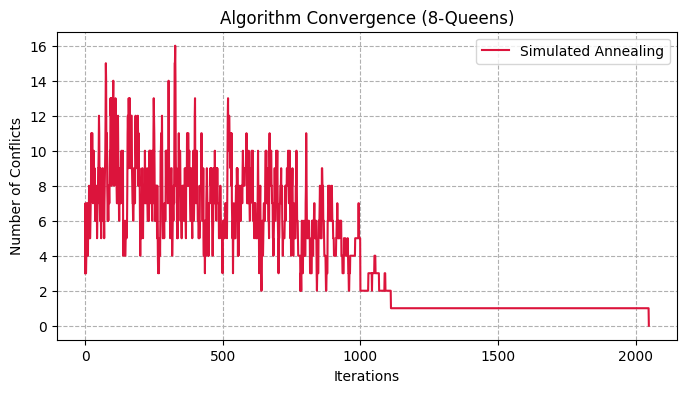

In [11]:
n = 8
init_b = random_board(n)
_, _, sa_hist = simulated_annealing(init_b)

plt.figure(figsize=(8, 4))
plt.plot(sa_hist, label='Simulated Annealing', color='crimson')
plt.title('Algorithm Convergence (8-Queens)')
plt.xlabel('Iterations')
plt.ylabel('Number of Conflicts')
plt.grid(True, linestyle='--')
plt.legend()
plt.show()

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

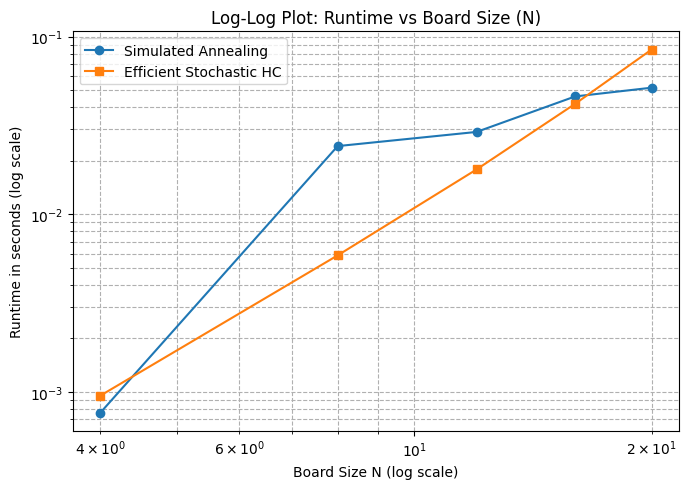

Note: 3 repetitions per n for practical runtime; use more repetitions for a formal performance study.


In [12]:
# Empirical scalability plot. Limit repetitions and failed-neighbor attempts so the cell is practical.
sizes = [4, 8, 12, 16, 20]
sa_times = []
hc_times = []
for n in sizes:
    t0 = time.perf_counter()
    for _ in range(3):
        simulated_annealing(random_board(n), max_steps=3000)
    sa_times.append((time.perf_counter() - t0) / 3)
    t0 = time.perf_counter()
    for _ in range(3):
        efficient_stochastic_hill_climbing(random_board(n), max_attempts_factor=5)
    hc_times.append((time.perf_counter() - t0) / 3)
plt.figure(figsize=(7, 5))
plt.loglog(sizes, sa_times, 'o-', label='Simulated Annealing')
plt.loglog(sizes, hc_times, 's-', label='Efficient Stochastic HC')
plt.title('Log-Log Plot: Runtime vs Board Size (N)')
plt.xlabel('Board Size N (log scale)')
plt.ylabel('Runtime in seconds (log scale)')
plt.grid(True, which="both", linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()
print('Note: 3 repetitions per n for practical runtime; use more repetitions for a formal performance study.')


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?


KẾT QUẢ THỰC NGHIỆM N = 8 (100 RUNS)


/tmp/ipykernel_723/3877753143.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_costs, labels=list(operators.keys()))


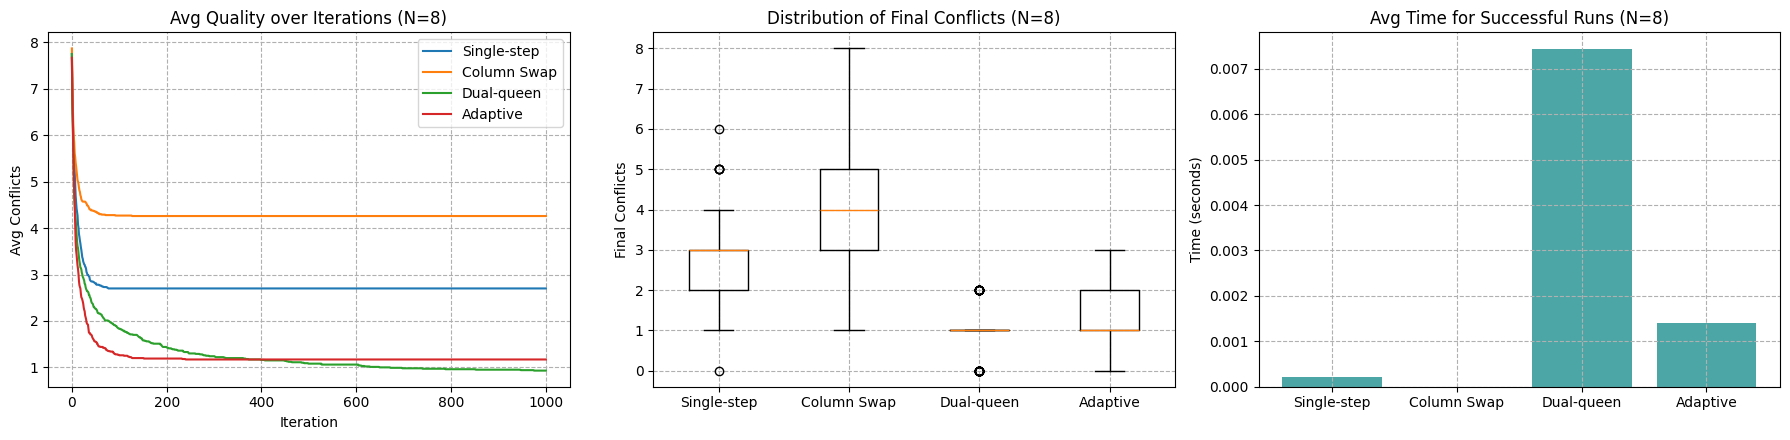


KẾT QUẢ THỰC NGHIỆM N = 12 (100 RUNS)


/tmp/ipykernel_723/3877753143.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_costs, labels=list(operators.keys()))


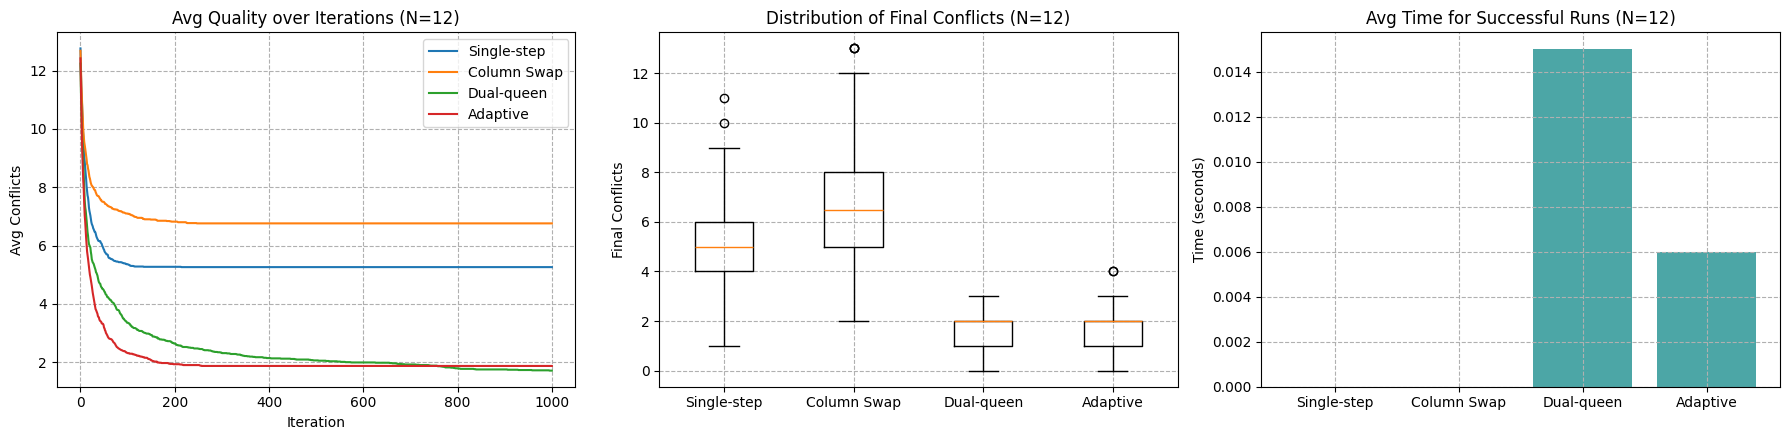

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import time

def single_step_move(board):
    """Di chuyển 1 quân hậu lên hoặc xuống đúng 1 ô."""
    curr = board.copy()
    col = np.random.randint(0, len(curr))
    step = np.random.choice([-1, 1])
    curr[col] = (curr[col] + step) % len(curr)
    return curr

def column_swap_move(board):
    """Tráo đổi vị trí quân hậu ở 2 cột ngẫu nhiên."""
    curr = board.copy()
    c1, c2 = np.random.choice(len(curr), size=2, replace=False)
    curr[c1], curr[c2] = curr[c2], curr[c1]
    return curr

def dual_queen_move(board):
    """Thay đổi vị trí của 2 quân hậu cùng một lúc."""
    curr = board.copy()
    c1, c2 = np.random.choice(len(curr), size=2, replace=False)
    curr[c1] = np.random.randint(0, len(curr))
    curr[c2] = np.random.randint(0, len(curr))
    return curr

def adaptive_move(board):
    """Ưu tiên di chuyển các quân hậu đang bị xung đột nhiều nhất."""
    curr = board.copy()
    n = len(curr)
    conf_per_col = np.zeros(n)
    for i in range(n):
        for j in range(i + 1, n):
            if curr[i] == curr[j] or abs(curr[i] - curr[j]) == j - i:
                conf_per_col[i] += 1
                conf_per_col[j] += 1
                
    if conf_per_col.sum() == 0:
        return curr
        
    probs = conf_per_col / conf_per_col.sum()
    chosen_col = np.random.choice(n, p=probs)
    curr[chosen_col] = np.random.randint(0, n)
    return curr

def stochastic_hc_with_op(n, op_fn, max_steps=1000):
    board = random_board(n)
    curr_cost = conflicts(board)
    cost_hist = [curr_cost]
    
    t0 = time.perf_counter()
    for step in range(max_steps):
        if curr_cost == 0:
            break
        neighbor = op_fn(board)
        new_cost = conflicts(neighbor)
        if new_cost < curr_cost:
            board = neighbor
            curr_cost = new_cost
        cost_hist.append(curr_cost)
    t1 = time.perf_counter()
    
    return board, curr_cost, cost_hist, (t1 - t0)

operators = {
    "Single-step": single_step_move,
    "Column Swap": column_swap_move,
    "Dual-queen": dual_queen_move,
    "Adaptive": adaptive_move
}

for n in [8, 12]:
    print(f"\nKẾT QUẢ THỰC NGHIỆM N = {n} (100 RUNS)")
    results = {op: {"final_costs": [], "times": [], "hists": []} for op in operators}
    
    for op_name, op_fn in operators.items():
        for _ in range(100):
            _, cost, hist, duration = stochastic_hc_with_op(n, op_fn)
            results[op_name]["final_costs"].append(cost)
            results[op_name]["times"].append(duration)
            results[op_name]["hists"].append(hist)

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    for op_name in operators:
        max_len = max(len(h) for h in results[op_name]["hists"])
        padded = np.array([h + [h[-1]]*(max_len - len(h)) for h in results[op_name]["hists"]])
        axes[0].plot(padded.mean(axis=0), label=op_name)
    axes[0].set_title(f'Avg Quality over Iterations (N={n})')
    axes[0].set_xlabel('Iteration')
    axes[0].set_ylabel('Avg Conflicts')
    axes[0].legend()
    axes[0].grid(True, linestyle='--')

    data_costs = [results[op]["final_costs"] for op in operators]
    axes[1].boxplot(data_costs, labels=list(operators.keys()))
    axes[1].set_title(f'Distribution of Final Conflicts (N={n})')
    axes[1].set_ylabel('Final Conflicts')
    axes[1].grid(True, linestyle='--')
   
    succ_times = []
    for op_name in operators:
        s_t = [t for c, t in zip(results[op_name]["final_costs"], results[op_name]["times"]) if c == 0]
        succ_times.append(np.mean(s_t) if len(s_t) > 0 else 0)
    axes[2].bar(list(operators.keys()), succ_times, color='teal', alpha=0.7)
    axes[2].set_title(f'Avg Time for Successful Runs (N={n})')
    axes[2].set_ylabel('Time (seconds)')
    axes[2].grid(True, linestyle='--')
    
    plt.tight_layout()
    plt.show()




### Nhận xét thí nghiệm toán tử di chuyển

- Single-step chỉ thay đổi hàng của một quân hậu một ô mỗi lần nên có thể tiến triển chậm.
- Column Swap hoán đổi hai giá trị hàng; do đó nó bảo toàn đa tập các hàng nhưng không nhất thiết giảm xung đột.
- Dual-queen thay đổi hai quân hậu cùng lúc, tạo bước nhảy lớn hơn nhưng cũng có thể làm tăng xung đột.
- Adaptive ưu tiên cột có nhiều xung đột; hiệu quả thực tế cần được xác định từ tỷ lệ thành công, xung đột cuối và thời gian đo được. Không kết luận một toán tử tốt nhất nếu chưa có số liệu đối chứng.


## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [14]:
import random
import numpy as np

def genetic_algorithm(n=8, pop_size=100, max_generations=1000, mutation_rate=0.1):
    def fitness(ind):
        max_pairs = n * (n - 1) // 2
        return max_pairs - conflicts(ind)

    def crossover(p1, p2):
        c = random.randint(1, n - 1)
        return np.concatenate([p1[:c], p2[c:]])

    def mutate(ind):
        if random.random() < mutation_rate:
            col = random.randint(0, n - 1)
            ind[col] = random.randint(0, n - 1)
        return ind

    population = [random_board(n) for _ in range(pop_size)]
    
    for gen in range(max_generations):
        fits = [fitness(ind) for ind in population]
        max_fit = max(fits)
        
        if max_fit == n * (n - 1) // 2:
            best_idx = fits.index(max_fit)
            print(f"-> Genetic Algorithm tìm thấy lời giải hoàn hảo ở thế hệ {gen}!")
            return population[best_idx], gen
            
        fit_probs = np.array(fits) / sum(fits)
        new_pop = []
        for _ in range(pop_size):
            p1 = population[np.random.choice(pop_size, p=fit_probs)]
            p2 = population[np.random.choice(pop_size, p=fit_probs)]
            child = mutate(crossover(p1, p2))
            new_pop.append(child)
            
        population = new_pop
        
    return population[0], max_generations

sol, gen_count = genetic_algorithm(n=8)
print(f"Nghiệm tìm được: {sol} | Số xung đột: {conflicts(sol)}")

-> Genetic Algorithm tìm thấy lời giải hoàn hảo ở thế hệ 60!
Nghiệm tìm được: [4 2 0 5 7 1 3 6] | Số xung đột: 0


## Thực nghiệm bổ sung theo yêu cầu đề Lab 04

Bảng benchmark dưới đây bổ sung Random Restart, thống kê số lần đánh giá hàm mục tiêu và số bước. Với mỗi thuật toán, `success rate` là tỷ lệ lần chạy có h = 0; `mean final h` là xung đột trung bình ở trạng thái trả về. Đây là số liệu thực nghiệm của môi trường chạy hiện tại, không phải bảo đảm lý thuyết.

In [15]:
import time, math, pandas as pd

# Implementations with explicit step/evaluation accounting for a fairer comparison.
def queen_conflicts_counted(board, counter):
    counter[0] += 1
    return conflicts(board)

def hc_traced(board, mode='steepest', max_steps=10000):
    cur = np.array(board, copy=True); n=len(cur); steps=0; evals=0; hist=[]
    cost=conflicts(cur); evals+=1; hist.append(cost)
    while cost > 0 and steps < max_steps:
        if mode == 'steepest':
            best=None; best_cost=cost
            for col in range(n):
                old=cur[col]
                for row in range(n):
                    if row == old: continue
                    cur[col]=row; c=conflicts(cur); evals+=1
                    if c < best_cost: best_cost=c; best=(col,row)
                cur[col]=old
            if best is None: break
            cur[best[0]]=best[1]; cost=best_cost
        elif mode == 'inefficient':
            improving=[]
            for col in range(n):
                old=cur[col]
                for row in range(n):
                    if row == old: continue
                    cur[col]=row; c=conflicts(cur); evals+=1
                    if c < cost: improving.append((col,row))
                cur[col]=old
            if not improving: break
            col,row=improving[np.random.randint(len(improving))]; cur[col]=row; cost=conflicts(cur); evals+=1
        else: # efficient stochastic: sample a neighbor; stop after a bounded number of failed proposals
            failures=0; accepted=False
            while failures < max(20, 20*n):
                col=np.random.randint(n); row=np.random.randint(n-1); row += (row >= cur[col])
                old=cur[col]; cur[col]=row; c=conflicts(cur); evals+=1
                if c < cost:
                    cost=c; accepted=True; break
                cur[col]=old; failures+=1
            if not accepted: break
        steps+=1; hist.append(cost)
    return cur, int(cost), steps, evals, hist

def sa_traced(board, max_steps=10000, initial_temp=100.0, cooling_rate=0.995):
    cur=np.array(board,copy=True); n=len(cur); cost=conflicts(cur); evals=1; hist=[cost]; temp=initial_temp; steps=0
    for _ in range(max_steps):
        if cost==0 or temp < 1e-8: break
        col=np.random.randint(n); row=np.random.randint(n-1); row += (row >= cur[col])
        old=cur[col]; cur[col]=row; new=conflicts(cur); evals+=1
        delta=new-cost
        if delta <= 0 or np.random.random() < math.exp(-delta/temp): cost=new
        else: cur[col]=old
        hist.append(cost); temp*=cooling_rate; steps+=1
    return cur, int(cost), steps, evals, hist

def restart_traced(n, max_restarts=20):
    best=None; best_cost=float('inf'); total_steps=0; total_evals=0; used=0
    for _ in range(max_restarts):
        used+=1; b,c,s,e,_=hc_traced(random_board(n), mode='steepest')
        total_steps+=s; total_evals+=e
        if c < best_cost: best,best_cost=b,c
        if c==0: break
    return best, int(best_cost), total_steps, total_evals, used

# 100 trials per requested size. A fixed seed makes this run repeatable.
np.random.seed(20261016)
bench_rows=[]
for n in [4,8]:
    for algo in ['Steepest HC','Inefficient Stochastic HC','Efficient Stochastic HC','Random Restart HC','Simulated Annealing']:
        for run in range(100):
            init=random_board(n); t0=time.perf_counter()
            if algo=='Steepest HC': b,c,s,e,h=hc_traced(init,'steepest')
            elif algo=='Inefficient Stochastic HC': b,c,s,e,h=hc_traced(init,'inefficient')
            elif algo=='Efficient Stochastic HC': b,c,s,e,h=hc_traced(init,'efficient')
            elif algo=='Random Restart HC': b,c,s,e,r=restart_traced(n,20); h=[]
            else: b,c,s,e,h=sa_traced(init)
            elapsed=time.perf_counter()-t0
            bench_rows.append({'n':n,'algorithm':algo,'run':run+1,'success':c==0,'final_h':c,'steps':s,'evaluations':e,'time_s':elapsed})
bench_df=pd.DataFrame(bench_rows)
bench_summary=bench_df.groupby(['n','algorithm'],as_index=False).agg(
    success_rate_pct=('success',lambda x:100*x.mean()), mean_final_h=('final_h','mean'),
    mean_steps=('steps','mean'), mean_evaluations=('evaluations','mean'), mean_time_s=('time_s','mean'))
for col in ['success_rate_pct','mean_final_h','mean_steps','mean_evaluations','mean_time_s']:
    bench_summary[col]=bench_summary[col].round(4)
display(bench_summary)

# Compare two cooling schedules over 100 independent runs at n=8.
np.random.seed(20261017)
sa_rows=[]
for label, temp, rate in [('Fast cooling (T0=100, alpha=0.98)',100.0,0.98),('Slow cooling (T0=100, alpha=0.995)',100.0,0.995)]:
    for run in range(100):
        t0=time.perf_counter(); b,c,s,e,h=sa_traced(random_board(8),initial_temp=temp,cooling_rate=rate); elapsed=time.perf_counter()-t0
        sa_rows.append({'schedule':label,'success':c==0,'final_h':c,'steps':s,'evaluations':e,'time_s':elapsed})
sa_df=pd.DataFrame(sa_rows)
sa_summary=sa_df.groupby('schedule',as_index=False).agg(success_rate_pct=('success',lambda x:100*x.mean()),mean_final_h=('final_h','mean'),mean_steps=('steps','mean'),mean_evaluations=('evaluations','mean'),mean_time_s=('time_s','mean'))
display(sa_summary.round(4))

,n,algorithm,success_rate_pct,mean_final_h,mean_steps,mean_evaluations,mean_time_s
0,4,Efficient Stochastic HC,29.0,0.86,1.81,69.66,0.0005
1,4,Inefficient Stochastic HC,42.0,0.73,1.89,32.53,0.0001
2,4,Random Restart HC,100.0,0.00,4.02,70.43,0.0003
3,4,Simulated Annealing,100.0,0.00,122.16,123.16,0.0010
4,4,Steepest HC,35.0,0.74,1.56,27.52,0.0001
5,8,Efficient Stochastic HC,15.0,1.24,4.72,202.60,0.0020
6,8,Inefficient Stochastic HC,13.0,1.33,5.07,338.71,0.0019
7,8,Random Restart HC,94.0,0.06,22.41,1605.31,0.0089
8,8,Simulated Annealing,96.0,0.04,1748.76,1749.76,0.0180
9,8,Steepest HC,22.0,1.09,3.34,231.72,0.0013


,schedule,success_rate_pct,mean_final_h,mean_steps,mean_evaluations,mean_time_s
0,"Fast cooling (T0=100, alpha=0.98)",80.0,0.20,730.84,731.84,0.0075
1,"Slow cooling (T0=100, alpha=0.995)",94.0,0.06,1762.84,1763.84,0.0184


### Đồ thị hội tụ đại diện tại n = 8

Mỗi đường biểu diễn số xung đột h theo bước của một lần chạy đại diện. Các thuật toán có quy tắc dừng khác nhau nên độ dài đường cong có thể khác nhau.

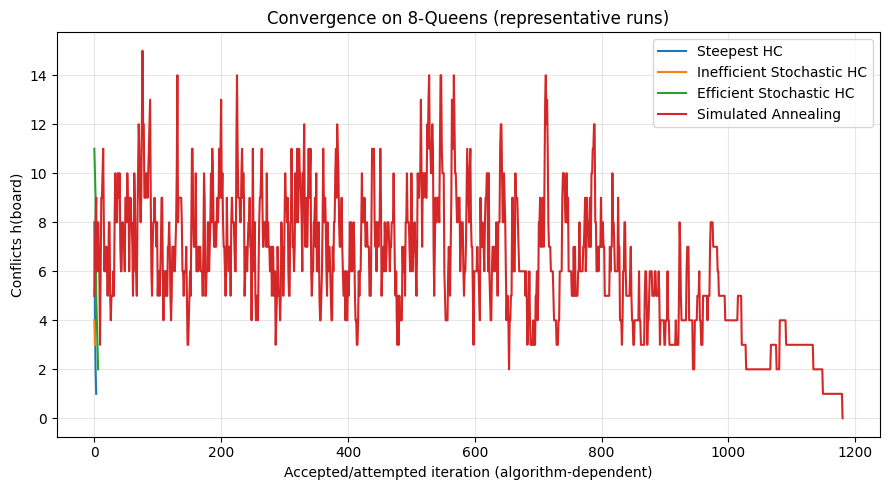

In [16]:
np.random.seed(20261018)
n=8
fig, ax=plt.subplots(figsize=(9,5))
init=random_board(n)
_,_,_,_,hist=hc_traced(init,'steepest'); ax.plot(hist,label='Steepest HC')
init=random_board(n)
_,_,_,_,hist=hc_traced(init,'inefficient'); ax.plot(hist,label='Inefficient Stochastic HC')
init=random_board(n)
_,_,_,_,hist=hc_traced(init,'efficient'); ax.plot(hist,label='Efficient Stochastic HC')
init=random_board(n)
_,_,_,_,hist=sa_traced(init,initial_temp=100,cooling_rate=0.995); ax.plot(hist,label='Simulated Annealing')
ax.set_title('Convergence on 8-Queens (representative runs)')
ax.set_xlabel('Accepted/attempted iteration (algorithm-dependent)'); ax.set_ylabel('Conflicts h(board)')
ax.grid(True,alpha=.3); ax.legend(); plt.tight_layout(); plt.show()